# Overall urine-flow effects: Vehicle and Empa − Vehicle

Posterior genotype, age, and sex contrasts, averaged equally over the other two factors.

The Empa − Vehicle model describes the treatment-associated **change in urine flow**; its contrasts describe how that change varies by genotype, age, or sex. They are not the overall treatment effect.


## Imports and fitted models

Uses the functions in `kidney.contrasts` (the attached `contrasts.py`). Ensure that file is installed or copied into your `kidney` package.


In [34]:
import arviz as az
import pandas as pd
import matplotlib.pyplot as plt

from kidney.contrasts import get_t_groups, get_overall_effects
from kidney.paths import RESULTS_DIR, PLOT_DIR
from kidney.plotting import forestplot_oz
from kidney.sign_probs import get_sign_probs, get_signif

plt.rcParams["pdf.fonttype"] = 42
az.rcParams["data.load"] = "eager"


## Overall contrasts using `kidney.contrasts`

The shared intercept cancels from each contrast. `get_overall_effects` averages across all levels of the other factors.


In [35]:
idata_vehicle = az.from_netcdf(RESULTS_DIR / "idata_urine_flow_vehicle.nc")
idata_change = az.from_netcdf(RESULTS_DIR / "idata_urine_flow_empa_minus_vehicle.nc")


In [36]:
ts_vehicle = get_overall_effects(get_t_groups(idata_vehicle))
ts_change = get_overall_effects(get_t_groups(idata_change))

## Plot overall effects

Text(0.5, 0, 'TS (Δ urine flow)')

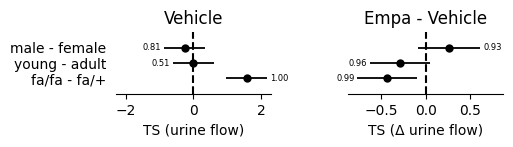

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(5, 0.8), sharey=True)
plt.subplots_adjust(wspace=0.5)

for ax, effects, title in zip(
    axes,
    (ts_vehicle, ts_change),
    ("Vehicle", "Empa - Vehicle"),
):
    forestplot_oz(ax, effects, sign_probs=True)
    ax.set_title(title)
    ax.spines[["top", "right", "left"]].set_visible(False)

axes[1].tick_params(axis="y", left=False, labelleft=False)

axes[0].set_xlabel("TS (urine flow)")
axes[1].set_xlabel("TS (\u0394 urine flow)")

fig.savefig(PLOT_DIR / "ts_UrineFlow_overall_effects.pdf", bbox_inches="tight")

## Posterior summaries and sign probabilities

In [38]:
sp_all = pd.DataFrame({
    "vehicle": get_sign_probs(ts_vehicle),
    "vehicle_signif": {
        k: get_signif(v)
        for k, v in get_sign_probs(ts_vehicle).items()
    },
    "empa - vehicle": get_sign_probs(ts_change),
    "empa - vehicle_signif": {
        k: get_signif(v)
        for k, v in get_sign_probs(ts_change).items()
    },
})

sp_all

,vehicle,vehicle_signif,empa - vehicle,empa - vehicle_signif
fa/fa - fa/+,1.0000,*,0.00600,*
young - adult,0.4920,,0.04075,
male - female,0.1855,,0.93075,
